# Contexta Research — 12 Ablations Error Analysis

Built on SenseForge shared modules. Run sequentially from the repository root or notebooks directory. Missing data is explicitly skipped; no fabricated results.

In [2]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))

ART = ROOT / "artifacts"
V2 = ART / "wsd_v2"
EVAL = ART / "evaluation_v2"
HYBRID = ART / "hybrid_v2"
OUT = ART / "ablation_v2"

OUT.mkdir(parents=True, exist_ok=True)

comparison = json.loads(
    (EVAL / "model_comparison.json").read_text(
        encoding="utf-8"
    )
)

test_rows = [
    json.loads(line)
    for line in (V2 / "test.jsonl").read_text(
        encoding="utf-8"
    ).splitlines()
    if line.strip()
]

SENSES = sorted({
    r["sense_id"]
    for r in test_rows
})

print("Test records:", len(test_rows))
print("Models:", list(comparison))
print("Sense classes:", len(SENSES))

assert len(test_rows) == 62
assert len(comparison) == 6

print("V2 ablation environment ready.")

Test records: 62
Models: ['Dictionary', 'Rule-Based', 'Logistic Regression', 'Residual MLP', 'XLM-R LoRA', 'Hybrid LoRA']
Sense classes: 12
V2 ablation environment ready.


In [4]:
summary = pd.DataFrame.from_dict(
    comparison,
    orient="index"
)

summary = summary.sort_values(
    "macro_f1",
    ascending=False
)

display(summary)

best_accuracy = summary["accuracy"].max()

print("Best accuracy:", best_accuracy)

print("\nModels achieving best accuracy:")
print(
    summary[
        summary["accuracy"] == best_accuracy
    ].index.tolist()
)

print("\nNeural vs Rule-Based improvement:")

for name in [
    "Logistic Regression",
    "Residual MLP",
    "XLM-R LoRA",
    "Hybrid LoRA"
]:
    gain = (
        comparison[name]["accuracy"]
        - comparison["Rule-Based"]["accuracy"]
    )

    print(f"{name:22}: {gain * 100:+.2f} percentage points")

,accuracy,macro_precision,macro_recall,macro_f1
Logistic Regression,1.000000,1.000000,1.000000,1.000000
Residual MLP,1.000000,1.000000,1.000000,1.000000
XLM-R LoRA,0.983871,0.992424,0.988095,0.989621
Hybrid LoRA,0.983871,0.992424,0.988095,0.989621
Rule-Based,0.467742,0.483692,0.561508,0.403322
Dictionary,0.387097,0.217495,0.500000,0.292284


Best accuracy: 1.0

Models achieving best accuracy:
['Logistic Regression', 'Residual MLP']

Neural vs Rule-Based improvement:
Logistic Regression   : +53.23 percentage points
Residual MLP          : +53.23 percentage points
XLM-R LoRA            : +51.61 percentage points
Hybrid LoRA           : +51.61 percentage points


In [6]:
models = [
    "Dictionary",
    "Rule-Based",
    "Logistic Regression",
    "Residual MLP",
    "XLM-R LoRA",
    "Hybrid LoRA"
]

records = []

for model_name in models:
    filename = (
        model_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    path = EVAL / f"{filename}_report.json"

    report = json.loads(
        path.read_text(encoding="utf-8")
    )

    for sense in SENSES:
        metrics = report[sense]

        records.append({
            "model": model_name,
            "sense": sense,
            "precision": metrics["precision"],
            "recall": metrics["recall"],
            "f1": metrics["f1-score"],
            "support": metrics["support"]
        })

per_sense = pd.DataFrame(records)

display(
    per_sense.pivot(
        index="sense",
        columns="model",
        values="f1"
    )
)

per_sense.to_csv(
    OUT / "per_sense_comparison.csv",
    index=False
)

print("Per-sense analysis saved.")

model,Dictionary,Hybrid LoRA,Logistic Regression,Residual MLP,Rule-Based,XLM-R LoRA
sense,,,,,,
bank.1,0.666667,1.000000,1.0,1.0,0.750000,1.000000
bank.2,0.000000,1.000000,1.0,1.0,0.500000,1.000000
interest.1,0.600000,1.000000,1.0,1.0,0.600000,1.000000
interest.2,0.000000,1.000000,1.0,1.0,0.000000,1.000000
plant.1,0.300000,1.000000,1.0,1.0,0.315789,1.000000
plant.2,0.000000,1.000000,1.0,1.0,0.133333,1.000000
point.1,0.740741,0.952381,1.0,1.0,0.740741,0.952381
point.2,0.000000,0.923077,1.0,1.0,0.000000,0.923077
right.1,0.800000,1.000000,1.0,1.0,0.800000,1.000000


Per-sense analysis saved.


In [8]:
path = EVAL / "model_disagreements.csv"

disagreements = pd.read_csv(path)

lora_errors = disagreements[
    disagreements["XLM-R LoRA"]
    != disagreements["gold"]
].copy()

print("Total disagreement rows:", len(disagreements))
print("LoRA errors:", len(lora_errors))

columns = [
    "record_id",
    "word",
    "sentence",
    "gold",
    "XLM-R LoRA",
    "Hybrid LoRA",
    "lora_confidence",
    "hybrid_used_neural"
]

display(lora_errors[columns])

lora_errors.to_csv(
    OUT / "lora_errors.csv",
    index=False
)

print("LoRA error taxonomy saved.")

Total disagreement rows: 38
LoRA errors: 1


,record_id,word,sentence,gold,XLM-R LoRA,Hybrid LoRA,lora_confidence,hybrid_used_neural
30,semcor_en:d088.s036.t010,point,"In the Analytical phase of their Cubism , Braq...",point.2,point.1,point.1,0.652746,False


LoRA error taxonomy saved.


In [10]:
fallbacks = disagreements[
    disagreements["hybrid_used_neural"] == False
].copy()

print("Hybrid fallback examples:", len(fallbacks))

if len(fallbacks):
    display(
        fallbacks[
            [
                "word",
                "sentence",
                "gold",
                "Rule-Based",
                "XLM-R LoRA",
                "Hybrid LoRA",
                "lora_confidence"
            ]
        ]
    )

    corrected = (
        (fallbacks["XLM-R LoRA"] != fallbacks["gold"])
        & (fallbacks["Hybrid LoRA"] == fallbacks["gold"])
    ).sum()

    harmed = (
        (fallbacks["XLM-R LoRA"] == fallbacks["gold"])
        & (fallbacks["Hybrid LoRA"] != fallbacks["gold"])
    ).sum()

    print("Errors corrected by fallback:", corrected)
    print("Correct predictions harmed:", harmed)

Hybrid fallback examples: 1


,word,sentence,gold,Rule-Based,XLM-R LoRA,Hybrid LoRA,lora_confidence
30,point,"In the Analytical phase of their Cubism , Braq...",point.2,point.1,point.1,point.1,0.652746


Errors corrected by fallback: 0
Correct predictions harmed: 0


In [14]:

import gc
import json
import numpy as np
import torch
import torch.nn as nn

from pathlib import Path
from transformers import AutoModel, AutoTokenizer
from peft import PeftModel
from torch.utils.data import Dataset, DataLoader

MODEL_NAME = "xlm-roberta-base"
MAX_LENGTH = 64
DEVICE = torch.device("cpu")

LORA = ART / "wsd_v2_lora"

# Match the exact label ordering used during training.
SENSES = [
    "bank.1", "bank.2",
    "interest.1", "interest.2",
    "plant.1", "plant.2",
    "point.1", "point.2",
    "right.1", "right.2",
    "table.1", "table.2"
]

class LoRAWSDClassifier(nn.Module):
    def __init__(self, encoder, num_classes):
        super().__init__()
        self.encoder = encoder
        hidden = encoder.config.hidden_size

        self.dropout = nn.Dropout(0.15)

        self.classifier = nn.Sequential(
            nn.Linear(hidden, 256),
            nn.GELU(),
            nn.Dropout(0.15),
            nn.Linear(256, num_classes)
        )

    def forward(
        self,
        input_ids,
        attention_mask,
        target_mask,
        class_mask=None
    ):
        hidden = self.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask
        ).last_hidden_state

        weights = target_mask.unsqueeze(-1)

        pooled = (
            (hidden * weights).sum(dim=1)
            / weights.sum(dim=1).clamp(min=1)
        )

        logits = self.classifier(
            self.dropout(pooled)
        )

        if class_mask is not None:
            logits = logits.masked_fill(
                ~class_mask.bool(),
                -1e4
            )

        return logits


tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    use_fast=True
)

base_encoder = AutoModel.from_pretrained(
    MODEL_NAME,
    attn_implementation="eager"
)

lora_encoder = PeftModel.from_pretrained(
    base_encoder,
    LORA / "best_lora_adapter",
    is_trainable=False
)

lora_model = LoRAWSDClassifier(
    lora_encoder,
    len(SENSES)
)

head_state = torch.load(
    LORA / "best_classifier_head.pt",
    map_location="cpu",
    weights_only=True
)

lora_model.classifier.load_state_dict(head_state)
lora_model.to(DEVICE)
lora_model.eval()

print("Best LoRA model loaded.")

class EvaluationDataset(Dataset):
    def __init__(self, rows):
        self.rows = rows

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows[index]

        text = row["text_en"]
        start = int(row["target_char_start"])
        end = int(row["target_char_end"])

        enc = tokenizer(
            text,
            add_special_tokens=True,
            truncation=False,
            return_offsets_mapping=True
        )

        ids = enc["input_ids"]
        offsets = enc["offset_mapping"]

        targets = [
            i for i, (a, b) in enumerate(offsets)
            if b > a and a < end and b > start
        ]

        if not targets:
            raise ValueError(
                f"Target alignment failed: {row['record_id']}"
            )

        capacity = MAX_LENGTH - 2
        first, last = targets[0], targets[-1]

        if last - first + 1 > capacity:
            raise ValueError("Target too long")

        left = max(
            1,
            first - capacity // 2
        )

        left = min(
            left,
            max(1, last - capacity + 1)
        )

        right = min(
            len(ids) - 1,
            left + capacity
        )

        if right - left < capacity:
            left = max(1, right - capacity)

        selected = list(range(left, right))
        target_set = set(targets)

        input_ids = (
            [ids[0]]
            + [ids[i] for i in selected]
            + [ids[-1]]
        )

        target_mask = (
            [0.0]
            + [
                float(i in target_set)
                for i in selected
            ]
            + [0.0]
        )

        attention = [1] * len(input_ids)

        pad = MAX_LENGTH - len(input_ids)

        assert pad >= 0
        assert sum(target_mask) > 0

        input_ids += [
            tokenizer.pad_token_id
        ] * pad

        attention += [0] * pad
        target_mask += [0.0] * pad

        word = row["target_word"]

        allowed = [
            sense.startswith(word + ".")
            for sense in SENSES
        ]

        assert sum(allowed) == 2

        return {
            "input_ids": torch.tensor(
                input_ids,
                dtype=torch.long
            ),
            "attention_mask": torch.tensor(
                attention,
                dtype=torch.long
            ),
            "target_mask": torch.tensor(
                target_mask,
                dtype=torch.float32
            ),
            "class_mask": torch.tensor(
                allowed,
                dtype=torch.bool
            )
        }


test_loader = DataLoader(
    EvaluationDataset(test_rows),
    batch_size=1,
    shuffle=False,
    num_workers=0
)

print("Test records:", len(test_loader))
print("Sense classes:", len(SENSES))
print("Device:", DEVICE)
print("Evaluation environment ready.")


Best LoRA model loaded.
Test records: 62
Sense classes: 12
Device: cpu
Evaluation environment ready.


In [16]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

lora_model.eval()

restricted = []
unrestricted = []
truth = []

with torch.inference_mode():
    for i, batch in enumerate(test_loader):
        logits = lora_model(
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"],
            target_mask=batch["target_mask"],
            class_mask=None
        )

        unrestricted_id = logits.argmax(
            dim=-1
        ).item()

        restricted_logits = logits.masked_fill(
            ~batch["class_mask"].bool(),
            -1e4
        )

        restricted_id = restricted_logits.argmax(
            dim=-1
        ).item()

        unrestricted.append(unrestricted_id)
        restricted.append(restricted_id)

        truth.append(
            SENSES.index(
                test_rows[i]["sense_id"]
            )
        )

        if (i + 1) % 20 == 0:
            print(
                f"Processed {i + 1}/{len(test_loader)}"
            )

labels = list(range(len(SENSES)))

ablation_results = {}

for name, predictions in [
    ("lemma_restricted", restricted),
    ("unrestricted", unrestricted)
]:
    ablation_results[name] = {
        "accuracy": float(
            accuracy_score(truth, predictions)
        ),
        "macro_precision": float(
            precision_score(
                truth, predictions,
                labels=labels,
                average="macro",
                zero_division=0
            )
        ),
        "macro_recall": float(
            recall_score(
                truth, predictions,
                labels=labels,
                average="macro",
                zero_division=0
            )
        ),
        "macro_f1": float(
            f1_score(
                truth, predictions,
                labels=labels,
                average="macro",
                zero_division=0
            )
        )
    }

print("\n=== LEMMA RESTRICTION ABLATION ===")

for name, metrics in ablation_results.items():
    print(f"\n{name}")

    for metric, value in metrics.items():
        print(f"{metric}: {value:.4f}")

changed = sum(
    a != b
    for a, b in zip(restricted, unrestricted)
)

print("\nPredictions changed:", changed)
print("Total examples:", len(truth))


Processed 20/62
Processed 40/62
Processed 60/62

=== LEMMA RESTRICTION ABLATION ===

lemma_restricted
accuracy: 0.9839
macro_precision: 0.9924
macro_recall: 0.9881
macro_f1: 0.9896

unrestricted
accuracy: 0.9032
macro_precision: 0.8708
macro_recall: 0.9100
macro_f1: 0.8682

Predictions changed: 6
Total examples: 62


In [18]:

import pandas as pd

changed_rows = []

for i, (restricted_id, unrestricted_id) in enumerate(
    zip(restricted, unrestricted)
):
    if restricted_id != unrestricted_id:
        row = test_rows[i]

        changed_rows.append({
            "record_id": row["record_id"],
            "word": row["target_word"],
            "sentence": row["text_en"],
            "gold": row["sense_id"],
            "restricted": SENSES[restricted_id],
            "unrestricted": SENSES[unrestricted_id],
            "restricted_correct": (
                restricted_id == truth[i]
            ),
            "unrestricted_correct": (
                unrestricted_id == truth[i]
            )
        })

changed_df = pd.DataFrame(changed_rows)

print("Changed predictions:", len(changed_df))

if not changed_df.empty:
    display(changed_df)

    changed_df.to_csv(
        OUT / "lemma_ablation_changed_predictions.csv",
        index=False
    )

print("Ablation error inspection complete.")


Changed predictions: 6


,record_id,word,sentence,gold,restricted,unrestricted,restricted_correct,unrestricted_correct
0,d078.s042.t009,bank,When he remembered that he might have not sign...,bank.1,bank.1,interest.1,True,False
1,d060.s084.t007,table,These deductions may not be claimed if you ele...,table.2,table.2,interest.1,True,False
2,semcor_en:d088.s036.t010,point,"In the Analytical phase of their Cubism , Braq...",point.2,point.1,plant.2,False,False
3,semcor_en:d138.s093.t003,interest,"Look at the trees as to size and interest , th...",interest.2,interest.2,bank.2,True,False
4,semcor_en:d170.s068.t003,point,Start by falling forward to a point close to t...,point.1,point.1,right.2,True,False
5,semcor_en:d128.s069.t019,point,This is brought out in the common religious et...,point.2,point.2,right.1,True,False


Ablation error inspection complete.


In [20]:

from sklearn.metrics import classification_report

for name, predictions in [
    ("lemma_restricted", restricted),
    ("unrestricted", unrestricted)
]:
    ablation_results[name]["classification_report"] = (
        classification_report(
            truth,
            predictions,
            labels=labels,
            target_names=SENSES,
            output_dict=True,
            zero_division=0
        )
    )

ablation_results["metadata"] = {
    "model": "xlmr_lora_epoch2",
    "evaluation_split": "wsd_v2_test",
    "test_examples": len(truth),
    "ablation_type": "inference_time_class_mask",
    "predictions_changed": changed,
    "model_retrained": False
}

output_path = OUT / "lemma_restriction_ablation.json"

output_path.write_text(
    json.dumps(
        ablation_results,
        indent=2
    ),
    encoding="utf-8"
)

print("Results saved:", output_path)


Results saved: /Users/suvratsmacbookair/MyLocalFiles/NLP project/SenseForge/artifacts/ablation_v2/lemma_restriction_ablation.json


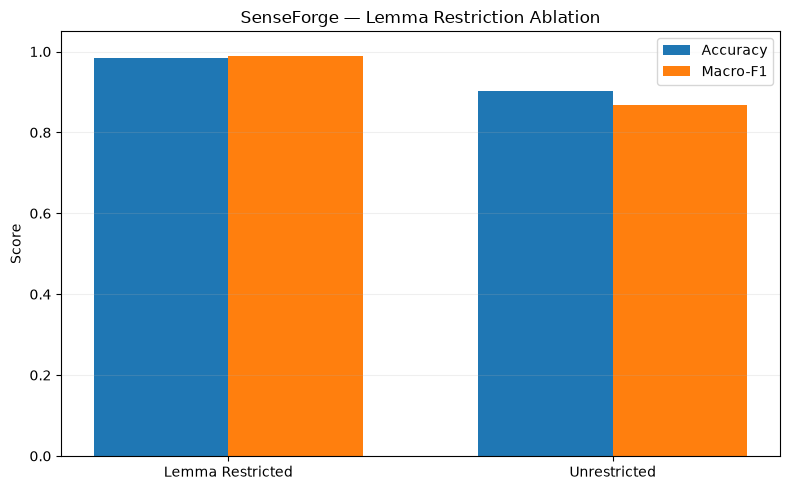

Ablation visualization saved.


In [22]:

import matplotlib.pyplot as plt

names = [
    "Lemma Restricted",
    "Unrestricted"
]

accuracies = [
    ablation_results["lemma_restricted"]["accuracy"],
    ablation_results["unrestricted"]["accuracy"]
]

macro_f1s = [
    ablation_results["lemma_restricted"]["macro_f1"],
    ablation_results["unrestricted"]["macro_f1"]
]

x = np.arange(len(names))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    x - width / 2,
    accuracies,
    width,
    label="Accuracy"
)

ax.bar(
    x + width / 2,
    macro_f1s,
    width,
    label="Macro-F1"
)

ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title(
    "SenseForge — Lemma Restriction Ablation"
)

ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

plt.savefig(
    OUT / "lemma_restriction_ablation.png",
    dpi=180
)

plt.show()

print("Ablation visualization saved.")
